In [ ]:
#Assignment 6. Design and implement a Convolutional Neural Network (CNN) for image classification using the Tomato or Soybean disease dataset.

In [ ]:
import kagglehub
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [ ]:
path = kagglehub.dataset_download("kaustubhb999/tomatoleaf")

print("Path to dataset files:", path)

IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 10

Using Colab cache for faster access to the 'tomatoleaf' dataset.
Path to dataset files: /kaggle/input/tomatoleaf


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

Found 11000 files belonging to 1 classes.
Using 8800 files for training.
Found 11000 files belonging to 1 classes.
Using 2200 files for validation.


In [ ]:
import os

print("Main folder:")
print(os.listdir(path))

for item in os.listdir(path):
    item_path = os.path.join(path, item)

    if os.path.isdir(item_path):
        print("\nInside", item, ":")
        print(os.listdir(item_path)[:20])

Main folder:
['tomato']

Inside tomato :
['cnn_train.py', 'val', 'train']


In [ ]:
import os

dataset_path = os.path.join(path, "tomato")

print("Dataset structure:\n")

print("tomato/")
print("├──", os.listdir(dataset_path))

train_path = os.path.join(dataset_path, "train")

print("\nTrain folder:")
if os.path.exists(train_path):
    train_classes = [
        item for item in os.listdir(train_path)
        if os.path.isdir(os.path.join(train_path, item))
    ]

    for cls in train_classes:
        image_count = len(os.listdir(os.path.join(train_path, cls)))
        print(f"├── {cls}/ ({image_count} images)")
else:
    print("❌ train folder not found")

val_path = os.path.join(dataset_path, "val")

print("\nValidation folder:")
if os.path.exists(val_path):
    val_classes = [
        item for item in os.listdir(val_path)
        if os.path.isdir(os.path.join(val_path, item))
    ]

    for cls in val_classes:
        image_count = len(os.listdir(os.path.join(val_path, cls)))
        print(f"├── {cls}/ ({image_count} images)")
else:
    print("❌ val folder not found")

print("\n--- Verification ---")

if os.path.exists(train_path) and os.path.exists(val_path):

    if set(train_classes) == set(val_classes):
        print("✅ Train and validation contain the same classes.")
    else:
        print("⚠️ Train and validation classes are different.")

    print("Number of training classes:", len(train_classes))
    print("Number of validation classes:", len(val_classes))

    print("\nTraining classes:")
    print(train_classes)

    print("\nValidation classes:")
    print(val_classes)

Dataset structure:

tomato/
├── ['cnn_train.py', 'val', 'train']

Train folder:
├── Tomato___Late_blight/ (1000 images)
├── Tomato___healthy/ (1000 images)
├── Tomato___Early_blight/ (1000 images)
├── Tomato___Septoria_leaf_spot/ (1000 images)
├── Tomato___Tomato_Yellow_Leaf_Curl_Virus/ (1000 images)
├── Tomato___Bacterial_spot/ (1000 images)
├── Tomato___Target_Spot/ (1000 images)
├── Tomato___Tomato_mosaic_virus/ (1000 images)
├── Tomato___Leaf_Mold/ (1000 images)
├── Tomato___Spider_mites Two-spotted_spider_mite/ (1000 images)

Validation folder:
├── Tomato___Late_blight/ (100 images)
├── Tomato___healthy/ (100 images)
├── Tomato___Early_blight/ (100 images)
├── Tomato___Septoria_leaf_spot/ (100 images)
├── Tomato___Tomato_Yellow_Leaf_Curl_Virus/ (100 images)
├── Tomato___Bacterial_spot/ (100 images)
├── Tomato___Target_Spot/ (100 images)
├── Tomato___Tomato_mosaic_virus/ (100 images)
├── Tomato___Leaf_Mold/ (100 images)
├── Tomato___Spider_mites Two-spotted_spider_mite/ (100 images

In [ ]:
# dataset_path = os.path.join(path, "tomato")

# train_path = os.path.join(dataset_path, "train")
# val_path = os.path.join(dataset_path, "val")

# print("Train path:", train_path)
# print("Validation path:", val_path)

# # Parameters
# IMG_SIZE = 128
# BATCH_SIZE = 32
# EPOCHS = 10

# Correct dataset paths
dataset_path = os.path.join(path, "tomato")

train_path = os.path.join(dataset_path, "train")
val_path = os.path.join(dataset_path, "val")

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Get class names
class_names = train_ds.class_names
num_classes = len(class_names)

print("\nClasses:")
for i, name in enumerate(class_names):
    print(i, ":", name)

print("\nNumber of classes:", num_classes)

Found 10000 files belonging to 10 classes.
Found 1000 files belonging to 10 classes.

Classes:
0 : Tomato___Bacterial_spot
1 : Tomato___Early_blight
2 : Tomato___Late_blight
3 : Tomato___Leaf_Mold
4 : Tomato___Septoria_leaf_spot
5 : Tomato___Spider_mites Two-spotted_spider_mite
6 : Tomato___Target_Spot
7 : Tomato___Tomato_Yellow_Leaf_Curl_Virus
8 : Tomato___Tomato_mosaic_virus
9 : Tomato___healthy

Number of classes: 10


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.cache().prefetch(
    buffer_size=AUTOTUNE
)

In [ ]:
model = models.Sequential([

    # Input layer
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Normalize pixel values
    layers.Rescaling(1./255),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Dropout
    layers.Dropout(0.3),

    # Flatten
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 331s 1s/step - accuracy: 0.8947 - loss: 0.2966 - val_accuracy: 0.8800 - val_loss: 0.3714
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 330s 1s/step - accuracy: 0.9050 - loss: 0.2692 - val_accuracy: 0.9010 - val_loss: 0.3518
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 330s 1s/step - accuracy: 0.9109 - loss: 0.2484 - val_accuracy: 0.8990 - val_loss: 0.3240
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 329s 1s/step - accuracy: 0.9214 - loss: 0.2164 - val_accuracy: 0.8930 - val_loss: 0.3594
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 329s 1s/step - accuracy: 0.9273 - loss: 0.2108 - val_accuracy: 0.8990 - val_loss: 0.3374
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 329s 1s/step - accuracy: 0.9341 - loss: 0.1869 - val_accuracy: 0.9120 - val_loss: 0.3217
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 329s 1s/step - accuracy: 0.9341 - loss: 0.1886 - val_accuracy: 0.8680 - val_loss: 0.5633
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 324s 1s/step - accuracy: 0.9325 - loss: 0.1890 - val_accu

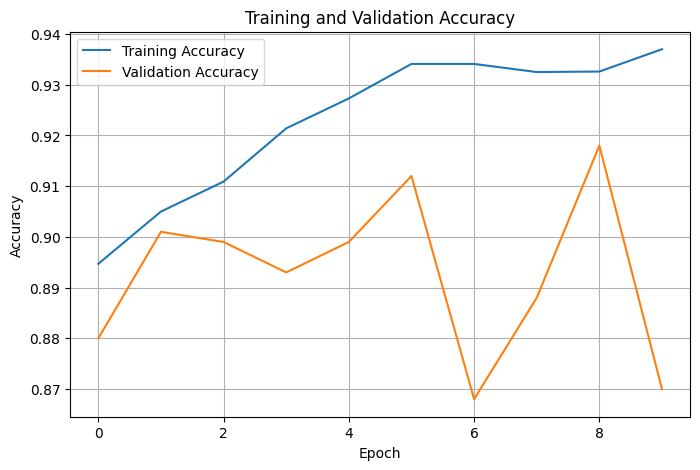

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)

plt.show()

In [15]:
# Evaluate the model on validation dataset
loss, accuracy = model.evaluate(val_ds)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 282ms/step - accuracy: 0.8700 - loss: 0.5091
Validation Loss: 0.5091055035591125
Validation Accuracy: 0.8700000047683716


In [16]:
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:

    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())

    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Number of true labels:", len(y_true))
print("Number of predictions:", len(y_pred))

Number of true labels: 1000
Number of predictions: 1000


In [17]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.85      0.96      0.90       100
                        Tomato___Early_blight       0.79      0.80      0.80       100
                         Tomato___Late_blight       0.73      0.93      0.82       100
                           Tomato___Leaf_Mold       0.92      0.78      0.84       100
                  Tomato___Septoria_leaf_spot       0.79      0.80      0.80       100
Tomato___Spider_mites Two-spotted_spider_mite       0.87      0.89      0.88       100
                         Tomato___Target_Spot       0.93      0.81      0.87       100
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.91      0.94      0.93       100
                 Tomato___Tomato_mosaic_virus       0.98      0.92      0.95       100
                             Tomato___healthy       1.00      0.87      0.93       100

                                     accu